# Prédire le nombre de trajets d'un déplacement (`NbTrajets`)
Enquête ménages-déplacements de Dakar — PySpark

**Plan** : 1. Chargement et cible → 2. Corrélation de **toutes** les colonnes avec la cible → 3. Choix des colonnes → 4. Analyse exploratoire → 5. Exploration par rapport à la cible → 6. Découpage → 7. Modèles et métriques → 8. Évaluation du modèle retenu

**Cible** : `NbTrajets` = nombre de trajets du déplacement (1, 2, 3 ou 4). C'est un problème de **classification à 4 classes**.

**Colonnes supprimées** : `Mode1`, `Mode2`, `Mode3`, `Mode4` sont retirées dès le chargement. `NbTrajets` est exactement le nombre de modes renseignés dans ces colonnes : les garder reviendrait à donner la réponse au modèle.

**Aucune colonne n'est créée** : le modèle n'utilise que des colonnes d'origine de la feuille `deplacement`.

**Découpage** : par ménage, pour ne pas mélanger un même ménage entre train et test
**Métriques** : accuracy, et precision, recall, F1-score (moyennes pondérées par le nombre de déplacements de chaque classe, puis détail par classe)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier

spark = (SparkSession.builder
         .master("local[*]") 
         .appName("nb_trajets")
         .config("spark.driver.memory", "6g")            
         .config("spark.sql.shuffle.partitions", "8")    
         .getOrCreate())

## 1. Chargement et cible
On charge la feuille `deplacement`, puis on **supprime `Mode1` à `Mode4`**. La cible est `NbTrajets`.

In [2]:
CHEMIN = "/home/jovyan/work/donnees_deplacement_PSpark_2026.xlsx"
if not os.path.exists(CHEMIN):          
    CHEMIN = "donnees_deplacement_PSpark_2026.xlsx"

pdf = pd.read_excel(CHEMIN, sheet_name="deplacement")
pdf = pdf.rename(columns={"Duree (mn)": "Duree_mn", "Moyen de transport": "Moyen_transport"})

# suppression de Mode1, Mode2, Mode3, Mode4 (elles définissent NbTrajets)
pdf = pdf.drop(columns=["Mode1", "Mode2", "Mode3", "Mode4"])

manquants = pdf.isna().mean()   

# colonnes texte : les manquants deviennent "manquant" (Spark n'aime pas les NaN dans du texte)
for col in pdf.select_dtypes(exclude="number").columns:
    pdf[col] = pdf[col].fillna("manquant")

df = spark.createDataFrame(pdf)
print(df.count(), "déplacements,", len(df.columns), "colonnes")

# cible  NbTrajets = 1, 2, 3 ou 4  to  classes 0, 1, 2, 3
N_CLASSES = 4
noms_classes = ["1 trajet", "2 trajets", "3 trajets", "4 trajets"]
df = df.withColumn("label", (F.col("NbTrajets") - 1).cast("double"))

df.groupBy("NbTrajets").count().orderBy("NbTrajets").show()

45605 déplacements, 29 colonnes
+---------+-----+
|NbTrajets|count|
+---------+-----+
|        1|37824|
|        2| 4616|
|        3| 2780|
|        4|  385|
+---------+-----+



## 2. Corrélation de toutes les colonnes avec la cible
Pour chaque colonne, on mesure son **lien avec la cible** (entre 0 et 1) :
- colonnes numériques : valeur absolue de la corrélation de Pearson (la cible est ordonnée : 1, 2, 3, 4 trajets) ;
- colonnes catégorielles : **V de Cramér** (avec beaucoup de modalités, comme `LieuDepart`, il est un peu gonflé) ;
- les identifiants (`numMena`, `num_individu`) et le poids d'enquête sont écartés : ils n'ont pas de sens ici.

On indique aussi pour chaque colonne **quand on la connaît** : `départ` (avant le déplacement), `après` (conséquence ou information d'arrivée) ou `fuite` (elle définit ou révèle la cible).

**2.1 Tableau de toutes les colonnes**

In [3]:
c = df.toPandas()

# colonnes qu'on n'analyse pas : identifiants, poids d'enquête, cible
a_ignorer = ["numMena", "num_individu", "Poids_extra", "label", "NbTrajets"]
codes = ["LieuDepart", "LieuArrivee"]   # numériques en apparence, mais ce sont des codes de zones

# moment où l'information est connue : `départ` = avant le déplacement (départ ET destination prévue)
fuite = ["Moyen_transport"] + [x for x in c.columns if x.startswith("NbTrajets") and x != "NbTrajets"]
apres = ["HeureArrivee", "Duree_mn", "Cout"]

lignes = []
for col in c.columns:
    if col in a_ignorer:
        continue

    if pd.api.types.is_numeric_dtype(c[col]) and col not in codes:
        # colonne numérique : valeur absolue de la corrélation avec la cible (ordonnée)
        type_col = "numérique"
        lien = abs(c[col].corr(c["label"]))
    else:
        # colonne catégorielle : V de Cramér (0 = aucun lien, 1 = lien parfait)
        type_col = "catégorielle"
        tab = pd.crosstab(c[col], c["label"])
        attendu = np.outer(tab.sum(axis=1), tab.sum(axis=0)) / tab.values.sum()
        chi2 = ((tab.values - attendu) ** 2 / attendu).sum()
        lien = (chi2 / tab.values.sum() / (min(tab.shape) - 1)) ** 0.5

    if col in fuite:
        connue = "fuite"
    elif col in apres:
        connue = "après"
    else:
        connue = "départ"

    lignes.append((col, type_col, connue, c[col].nunique(), round(manquants.get(col, 0), 2), round(lien, 3)))

table_col = pd.DataFrame(lignes, columns=["colonne", "type", "connue", "nb_valeurs", "part_manquante", "lien_cible"])
table_col = table_col.sort_values("lien_cible", ascending=False)

# décision automatique (à ajuster à la main ensuite)
conditions = [table_col["connue"] == "fuite", table_col["connue"] == "après", table_col["lien_cible"] < 0.05]
choix = ["exclure : fuite", "exclure : connue après", "écarter : lien faible"]
table_col["decision"] = np.select(conditions, choix, default="candidate")

print(table_col.to_string(index=False))

                  colonne         type connue  nb_valeurs  part_manquante  lien_cible               decision
          Moyen_transport catégorielle  fuite          11             0.0       0.535        exclure : fuite
                 Duree_mn    numérique  après         160             0.0       0.433 exclure : connue après
            NbTrajetsTata    numérique  fuite         104             0.0       0.414        exclure : fuite
       NbTrajetsCarRapide    numérique  fuite          87             0.0       0.298        exclure : fuite
          NbTrajetsClando    numérique  fuite          89             0.0       0.283        exclure : fuite
              NbTrajetsNN    numérique  fuite          77             0.0       0.240        exclure : fuite
               LieuDepart catégorielle départ         219             0.0       0.185              candidate
              LieuArrivee catégorielle départ         218             0.0       0.184              candidate
          num_Depla

**2.2 Graphique : lien de chaque colonne avec la cible**

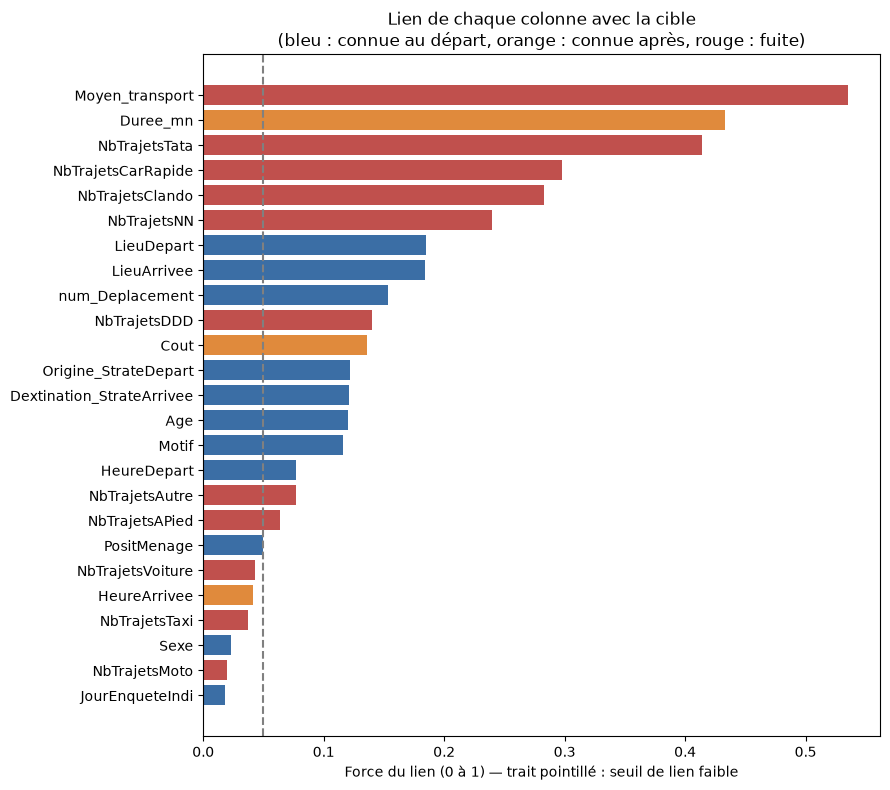

In [4]:
t = table_col.sort_values("lien_cible")
couleurs = t["connue"].map({"départ": "#3b6ea5", "après": "#e08a3c", "fuite": "#c0504d"}).tolist()

plt.figure(figsize=(9, 8))
plt.barh(t["colonne"], t["lien_cible"], color=couleurs)
plt.axvline(0.05, color="grey", linestyle="--")
plt.title("Lien de chaque colonne avec la cible\n(bleu : connue au départ, orange : connue après, rouge : fuite)")
plt.xlabel("Force du lien (0 à 1) — trait pointillé : seuil de lien faible")
plt.tight_layout()
plt.show()

**2.3 Corrélation entre toutes les colonnes numériques** (pour repérer les colonnes qui disent la même chose)

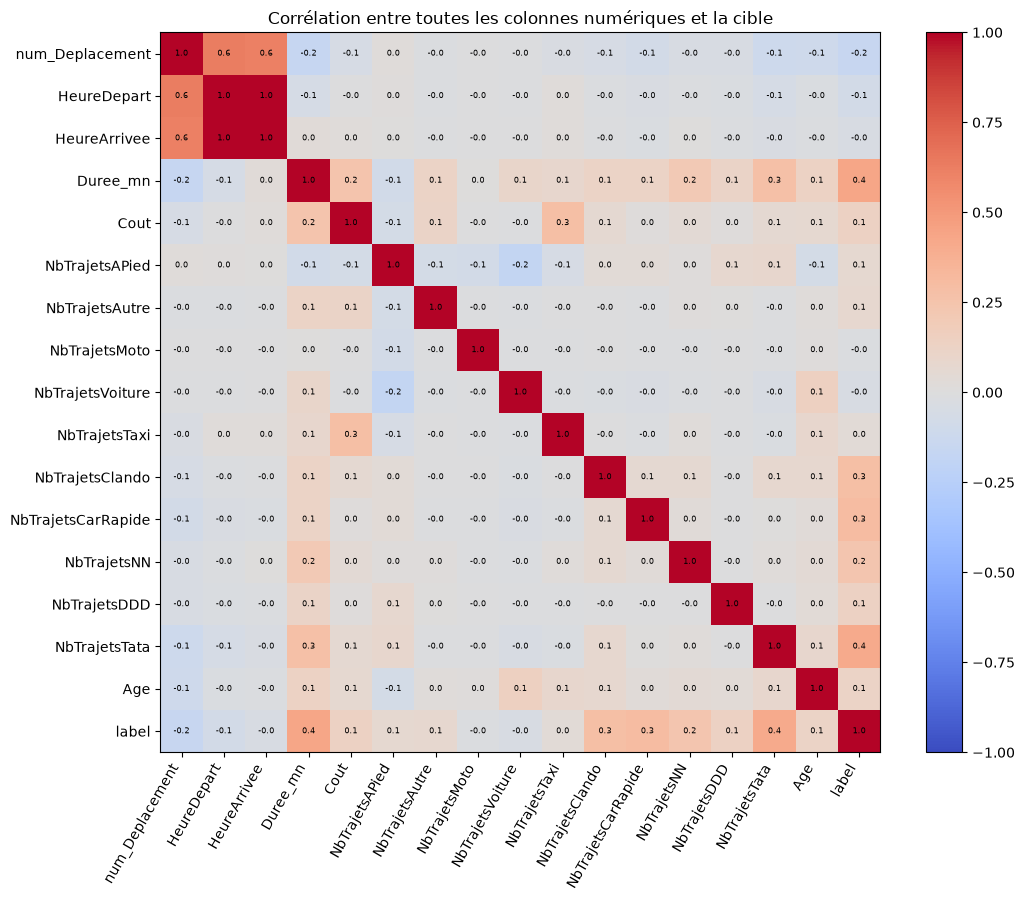

In [5]:
num_all = [x for x in c.columns if pd.api.types.is_numeric_dtype(c[x]) and x not in a_ignorer + codes]
matrice_corr = c[num_all + ["label"]].corr()

plt.figure(figsize=(11, 9))
plt.imshow(matrice_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(matrice_corr)), matrice_corr.columns, rotation=60, ha="right")
plt.yticks(range(len(matrice_corr)), matrice_corr.columns)
for i in range(len(matrice_corr)):
    for j in range(len(matrice_corr)):
        plt.text(j, i, round(matrice_corr.iloc[i, j], 1), ha="center", va="center", fontsize=6)
plt.title("Corrélation entre toutes les colonnes numériques et la cible")
plt.tight_layout()
plt.show()

**Lecture**
- **Fuite (rouge)** : `Moyen_transport` (« Intermodal » ou « APied » révèle presque le nombre de trajets, lien 0,54) et les colonnes `NbTrajets*` par mode (`NbTrajetsTata`, `NbTrajetsCarRapide`, etc.), qui découpent `NbTrajets` mode par mode. Les exclure est indispensable. `Mode1` à `Mode4` ont déjà été supprimées au chargement.
- **Connues après le déplacement (orange)** : `Duree_mn` (lien 0,43), `Cout`, `HeureArrivee`. On ne reprend que `Duree_mn`, dans un scénario séparé « avec durée ».
- **Connues avant le déplacement (bleu)** : les plus liées à la cible sont `LieuDepart`, `LieuArrivee` (≈ 0,18, un peu gonflé par leurs ~220 modalités), `num_Deplacement` (0,15), les strates de départ et d'arrivée, `Age`, `Motif` (≈ 0,12), puis `HeureDepart` et `PositMenage`.
- **Lien très faible** : `Sexe` et `JourEnqueteIndi` (< 0,05) : on les écarte.
- Les liens des colonnes de départ restent modestes (≤ 0,19) : il faut s'attendre à des scores corrects en accuracy mais difficiles sur les classes rares (3 et 4 trajets).

## 3. Choix des colonnes
On part des colonnes « candidate » du tableau. Aucune colonne n'est créée : on garde uniquement des colonnes d'origine, connues **avant** le déplacement (départ, destination prévue, motif, profil de la personne, rang du déplacement).

In [6]:
cat_cols = ["Origine_StrateDepart", "LieuDepart", "Dextination_StrateArrivee", "LieuArrivee",
            "Motif", "PositMenage"]
num_cols = ["Age", "HeureDepart", "num_Deplacement"]

print("Colonnes retenues :", cat_cols + num_cols)

Colonnes retenues : ['Origine_StrateDepart', 'LieuDepart', 'Dextination_StrateArrivee', 'LieuArrivee', 'Motif', 'PositMenage', 'Age', 'HeureDepart', 'num_Deplacement']


## 4. Analyse exploratoire du dataset

**4.1 Aperçu et qualité des données**

In [7]:
print("Déplacements :", df.count())
print("Ménages      :", df.select("numMena").distinct().count())
print("Individus    :", df.select("numMena", "num_individu").distinct().count())
df.printSchema()

# valeurs manquantes d'origine : colonnes concernées 
print(manquants[manquants > 0].round(2))

# doublons sur la clé (ménage, individu, déplacement)
print("Doublons :", df.count() - df.dropDuplicates(["numMena", "num_individu", "num_Deplacement"]).count())

Déplacements : 45605
Ménages      : 3127
Individus    : 11457
root
 |-- numMena: long (nullable = true)
 |-- num_individu: long (nullable = true)
 |-- num_Deplacement: long (nullable = true)
 |-- Poids_extra: double (nullable = true)
 |-- LieuDepart: long (nullable = true)
 |-- Origine_StrateDepart: string (nullable = true)
 |-- HeureDepart: long (nullable = true)
 |-- LieuArrivee: long (nullable = true)
 |-- Dextination_StrateArrivee: string (nullable = true)
 |-- HeureArrivee: long (nullable = true)
 |-- Duree_mn: long (nullable = true)
 |-- Motif: string (nullable = true)
 |-- NbTrajets: long (nullable = true)
 |-- Cout: double (nullable = true)
 |-- NbTrajetsAPied: double (nullable = true)
 |-- NbTrajetsAutre: double (nullable = true)
 |-- NbTrajetsMoto: double (nullable = true)
 |-- NbTrajetsVoiture: double (nullable = true)
 |-- NbTrajetsTaxi: double (nullable = true)
 |-- NbTrajetsClando: double (nullable = true)
 |-- NbTrajetsCarRapide: double (nullable = true)
 |-- NbTrajetsNN

**4.2 Statistiques descriptives**
`HeureDepart` est codée en HHMM et peut dépasser 2400 (déplacements après minuit).

In [8]:
df.select("Age", "HeureDepart", "Duree_mn").summary("min", "25%", "50%", "75%", "max", "mean").show()
print("Durées > 240 min                        :", df.filter(F.col("Duree_mn") > 240).count())
print("Heures de départ >= 2400 (après minuit) :", df.filter(F.col("HeureDepart") >= 2400).count())

+-------+------------------+------------------+-----------------+
|summary|               Age|       HeureDepart|         Duree_mn|
+-------+------------------+------------------+-----------------+
|    min|                11|               400|                1|
|    25%|                18|              1000|                5|
|    50%|                27|              1400|               10|
|    75%|                39|              1800|               23|
|    max|                95|              2757|              900|
|   mean|30.146014691371562|1397.6312465738406|18.64578445345905|
+-------+------------------+------------------+-----------------+

Durées > 240 min                        : 50
Heures de départ >= 2400 (après minuit) : 270


**4.3 Distribution des variables**

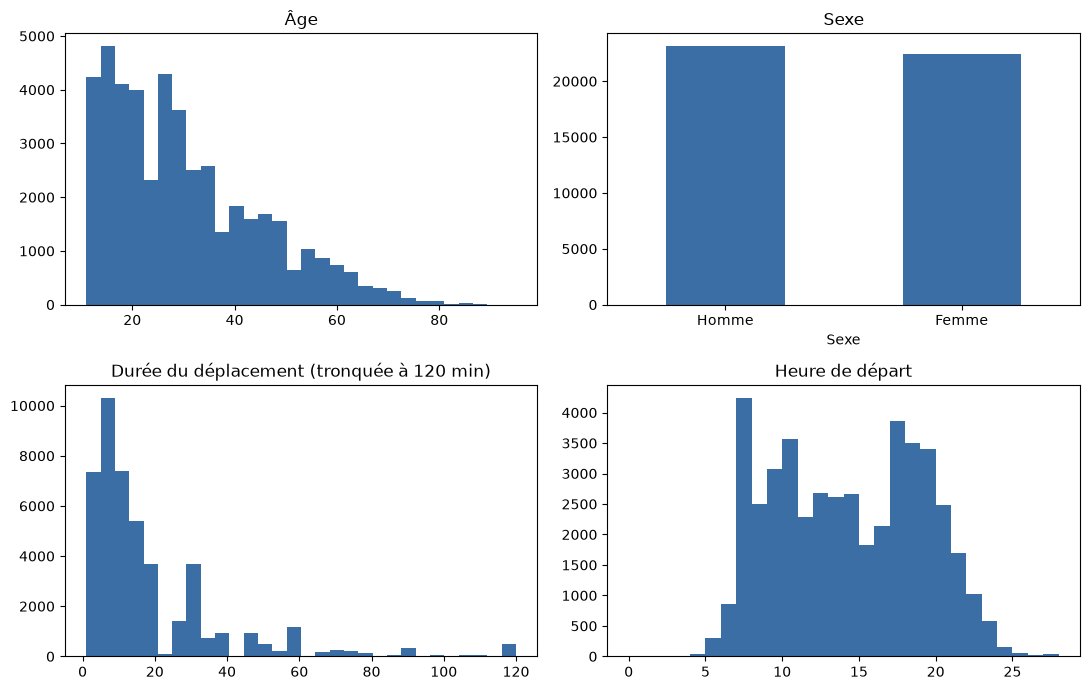

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(pdf["Age"], bins=30, color="#3b6ea5")
axes[0, 0].set_title("Âge")
pdf["Sexe"].value_counts().plot(kind="bar", ax=axes[0, 1], color="#3b6ea5", rot=0)
axes[0, 1].set_title("Sexe")
axes[1, 0].hist(pdf["Duree_mn"].clip(upper=120), bins=30, color="#3b6ea5")
axes[1, 0].set_title("Durée du déplacement (tronquée à 120 min)")
axes[1, 1].hist(pdf["HeureDepart"] // 100, bins=range(0, 29), color="#3b6ea5")
axes[1, 1].set_title("Heure de départ")
plt.tight_layout()
plt.show()

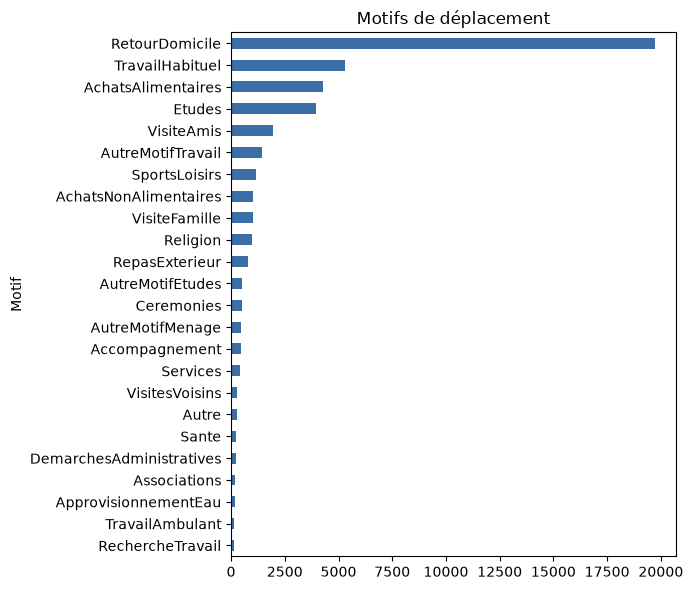

In [10]:
plt.figure(figsize=(7, 6))
pdf["Motif"].value_counts().sort_values().plot(kind="barh", color="#3b6ea5")
plt.title("Motifs de déplacement")
plt.tight_layout()
plt.show()

## 5. Exploration par rapport à la cible

**5.1 Répartition de la cible** : la classe « 1 trajet » domine largement (déséquilibre à gérer).

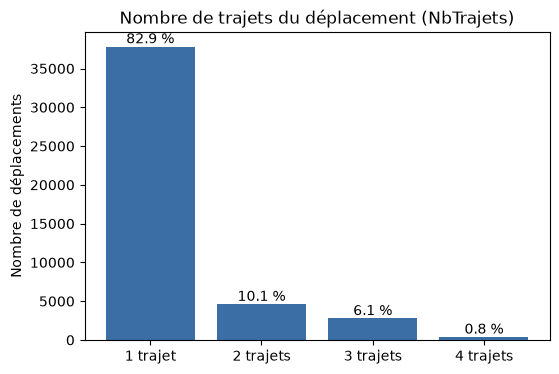

In [11]:
cible = df.groupBy("label").count().toPandas().sort_values("label")
plt.figure(figsize=(6, 4))
plt.bar(noms_classes, cible["count"], color="#3b6ea5")
for i, v in enumerate(cible["count"]):
    plt.text(i, v, str(round(100 * v / cible["count"].sum(), 1)) + " %", ha="center", va="bottom")
plt.title("Nombre de trajets du déplacement (NbTrajets)")
plt.ylabel("Nombre de déplacements")
plt.show()

**5.2 Par motif**

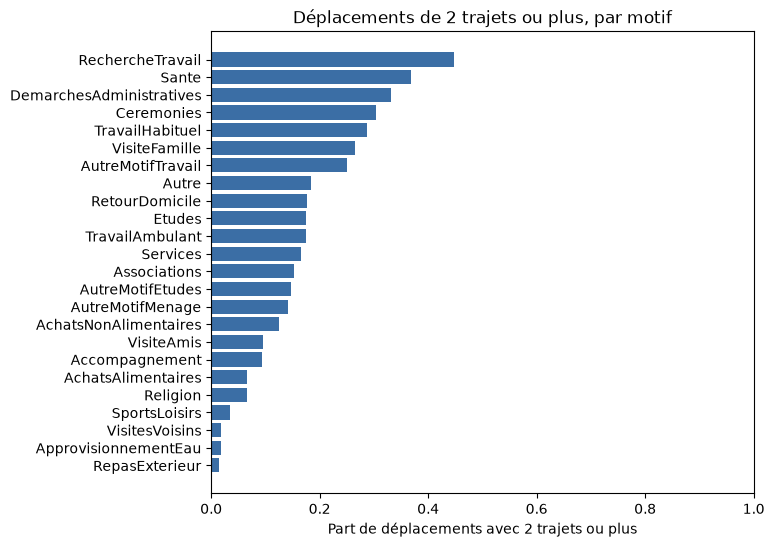

In [12]:
multi = (F.col("label") >= 1).cast("double")   # 1 si le déplacement a au moins 2 trajets
t_motif = (df.groupBy("Motif").agg(F.avg(multi).alias("taux_multi"))
          .toPandas().sort_values("taux_multi"))
plt.figure(figsize=(7, 6))
plt.barh(t_motif["Motif"].astype(str), t_motif["taux_multi"], color="#3b6ea5")
plt.title("Déplacements de 2 trajets ou plus, par motif")
plt.xlabel("Part de déplacements avec 2 trajets ou plus")
plt.xlim(0, 1)
plt.show()

**5.3 Par strate de départ**

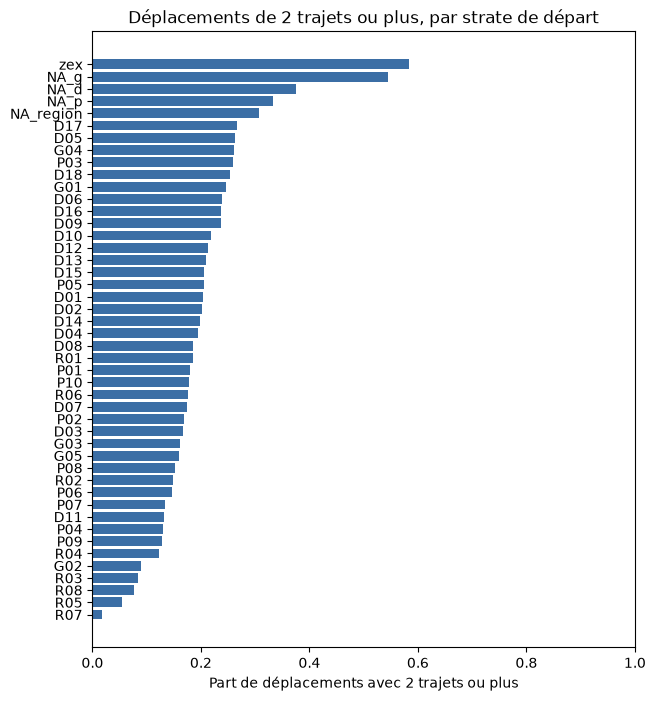

In [13]:
t_strate = (df.groupBy("Origine_StrateDepart").agg(F.avg(multi).alias("taux_multi"))
           .toPandas().sort_values("taux_multi"))
plt.figure(figsize=(7, 8))
plt.barh(t_strate["Origine_StrateDepart"].astype(str), t_strate["taux_multi"], color="#3b6ea5")
plt.title("Déplacements de 2 trajets ou plus, par strate de départ")
plt.xlabel("Part de déplacements avec 2 trajets ou plus")
plt.xlim(0, 1)
plt.show()

**5.4 Durée du déplacement** (information connue seulement après le déplacement, à titre d'exploration)

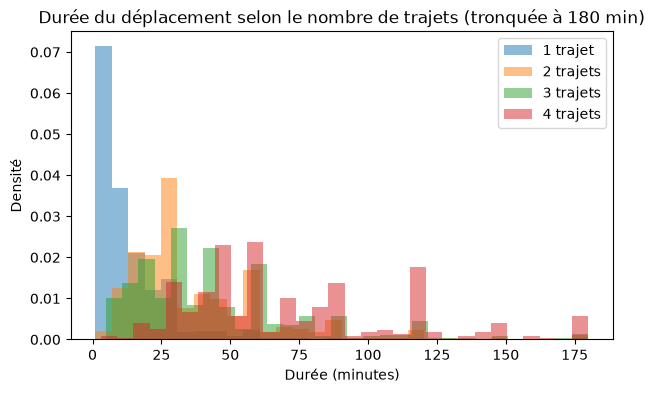

In [14]:
d = df.select("Duree_mn", "label").toPandas()
plt.figure(figsize=(7, 4))
for k, nom in enumerate(noms_classes):
    plt.hist(d[d["label"] == k]["Duree_mn"].clip(upper=180), bins=30, alpha=0.5, density=True, label=nom)
plt.title("Durée du déplacement selon le nombre de trajets (tronquée à 180 min)")
plt.xlabel("Durée (minutes)")
plt.ylabel("Densité")
plt.legend()
plt.show()

## 6. Découpage train / test par ménage
La classe « 1 trajet » domine (≈ 83 %). On peut donner un **poids plus fort aux classes rares** à l'apprentissage (`POIDS_CLASSES = True`) : le recall des classes rares monte, mais la precision et l'accuracy baissent. La valeur par défaut est `False`.

In [15]:
menages = df.select("numMena").distinct()
m_train, m_test = menages.randomSplit([0.8, 0.2], seed=42)

train = df.join(m_train, "numMena")
test = df.join(m_test, "numMena").cache()

POIDS_CLASSES = False   # True : poids plus forts pour les classes rares

# poids de classe = nombre total / (nombre de classes x effectif de la classe)
n = train.count()
effectifs = train.groupBy("label").count().toPandas()

train = train.withColumn("poids_classe", F.lit(1.0))
for _, ligne in effectifs.iterrows():
    poids = n / (N_CLASSES * ligne["count"])
    train = train.withColumn("poids_classe",
                             F.when(F.col("label") == ligne["label"], poids).otherwise(F.col("poids_classe")))
train = train.cache()

print("train :", train.count(), "| test :", test.count())
print(effectifs.sort_values("label"))

train : 37117 | test : 8488
   label  count
1    0.0  30919
0    1.0   3672
3    2.0   2225
2    3.0    301


## 7. Modèles et métriques
On compare deux modèles à **arbres** (arbre de décision et forêt aléatoire), sans puis avec la durée du déplacement. Les arbres gèrent directement les colonnes à nombreuses modalités (`LieuDepart`, `LieuArrivee` : environ 220 valeurs) : on les indexe avec `StringIndexer`, sans one-hot, et on règle `maxBins=256`. (Le `GBTClassifier` de Spark ne gère pas le multiclasse : il est retiré.)

Les classes sont très déséquilibrées : `precision`, `recall` et `f1` sont les moyennes **pondérées** par le nombre de déplacements de chaque classe (le recall pondéré est égal à l'accuracy). Le détail par classe est donné en section 8.

In [16]:
def calcul_metriques(p):
    """p : DataFrame pandas avec les colonnes label et prediction."""
    classes = [float(k) for k in range(N_CLASSES)]
    prec_k, rec_k, f1_k, support = [], [], [], []
    for k in classes:
        tp = ((p["label"] == k) & (p["prediction"] == k)).sum()
        fp = ((p["label"] != k) & (p["prediction"] == k)).sum()
        fn = ((p["label"] == k) & (p["prediction"] != k)).sum()
        pr = tp / (tp + fp) if tp + fp > 0 else 0
        rc = tp / (tp + fn) if tp + fn > 0 else 0
        prec_k.append(pr)
        rec_k.append(rc)
        f1_k.append(2 * pr * rc / (pr + rc) if pr + rc > 0 else 0)
        support.append((p["label"] == k).sum())
    w = np.array(support) / sum(support)
    accuracy = (p["label"] == p["prediction"]).mean()
    pondere = (accuracy, (w * prec_k).sum(), (w * rec_k).sum(), (w * f1_k).sum())
    return pondere, prec_k, rec_k, f1_k, support


poids = {"weightCol": "poids_classe"} if POIDS_CLASSES else {}

modeles = {
    "DecisionTree": DecisionTreeClassifier(labelCol="label", maxDepth=10, maxBins=256, seed=42, **poids),
    "RandomForest": RandomForestClassifier(labelCol="label", numTrees=50, maxDepth=10, maxBins=256, seed=42, **poids),
}

indexers = [StringIndexer(inputCol=x, outputCol=x + "_idx", handleInvalid="keep") for x in cat_cols]

resultats = []
predictions = {}

for scenario, colonnes_num in [("sans durée", num_cols),
                               ("avec durée", num_cols + ["Duree_mn"])]:
    assembler = VectorAssembler(inputCols=[x + "_idx" for x in cat_cols] + colonnes_num,
                                outputCol="features", handleInvalid="keep")

    for nom, modele in modeles.items():
        pipeline = Pipeline(stages=indexers + [assembler, modele])
        fitted = pipeline.fit(train)
        pred = fitted.transform(test)
        predictions[(scenario, nom)] = (fitted, pred)

        p = pred.select("label", "prediction").toPandas()
        (accuracy, precision, recall, f1), *_ = calcul_metriques(p)

        resultats.append((scenario, nom, accuracy, precision, recall, f1))
        print(scenario, "|", nom, "| accuracy =", round(accuracy, 3), "| f1 =", round(f1, 3))

tableau = pd.DataFrame(resultats, columns=["scenario", "modele", "accuracy", "precision", "recall", "f1"]).round(3)
tableau

sans durée | DecisionTree | accuracy = 0.804 | f1 = 0.775
sans durée | RandomForest | accuracy = 0.817 | f1 = 0.744
avec durée | DecisionTree | accuracy = 0.796 | f1 = 0.776
avec durée | RandomForest | accuracy = 0.824 | f1 = 0.776


,scenario,modele,accuracy,precision,recall,f1
0,sans durée,DecisionTree,0.804,0.758,0.804,0.775
1,sans durée,RandomForest,0.817,0.752,0.817,0.744
2,avec durée,DecisionTree,0.796,0.760,0.796,0.776
3,avec durée,RandomForest,0.824,0.762,0.824,0.776


**Comparaison des modèles** : accuracy et moyennes pondérées de precision, recall et F1.

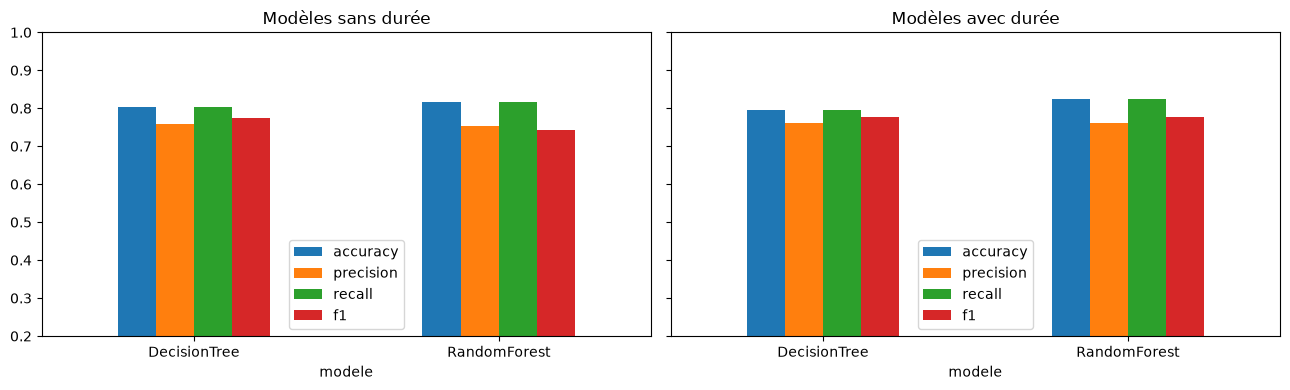

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, scen in zip(axes, ["sans durée", "avec durée"]):
    t = tableau[tableau["scenario"] == scen].set_index("modele")[["accuracy", "precision", "recall", "f1"]]
    t.plot(kind="bar", ax=ax, rot=0)
    ax.set_title("Modèles " + scen)
    ax.set_ylim(0.2, 1)
plt.tight_layout()
plt.show()

## 8. Évaluation du modèle retenu
On retient le modèle « sans durée » qui a le meilleur F1 pondéré (la durée n'est connue qu'après le déplacement).

**8.1 Matrice de confusion et rapport par classe**

Modèle retenu : DecisionTree
Accuracy : 0.804 | precision : 0.758 | recall : 0.804 | f1 : 0.775 (moyennes pondérées)
           precision  recall  f1-score  support
1 trajet       0.859   0.948     0.901     6905
2 trajets      0.337   0.186     0.240      944
3 trajets      0.315   0.191     0.238      555
4 trajets      0.083   0.012     0.021       84


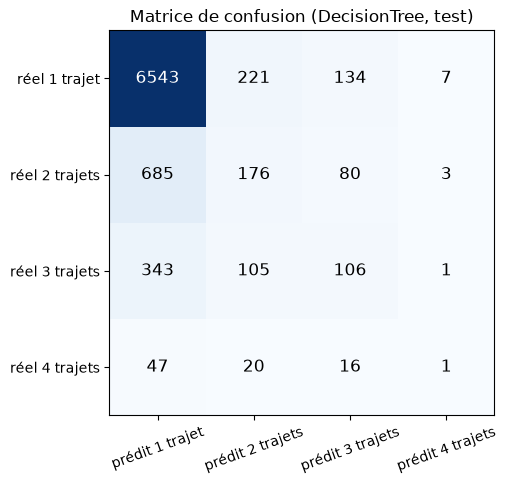

In [18]:
sans_duree = tableau[tableau["scenario"] == "sans durée"].sort_values("f1")
modele_retenu = sans_duree["modele"].iloc[-1]
fitted, pred = predictions[("sans durée", modele_retenu)]

p = pred.select("label", "prediction").toPandas()
classes = [float(k) for k in range(N_CLASSES)]
(accuracy, precision, recall, f1), prec_k, rec_k, f1_k, support = calcul_metriques(p)

matrice = pd.crosstab(p["label"], p["prediction"]).reindex(index=classes, columns=classes, fill_value=0)

# rapport par classe (comme classification_report)
rapport = pd.DataFrame({"precision": prec_k, "recall": rec_k, "f1-score": f1_k, "support": support},
                       index=noms_classes)

print("Modèle retenu :", modele_retenu)
print("Accuracy :", round(accuracy, 3), "| precision :", round(precision, 3),
      "| recall :", round(recall, 3), "| f1 :", round(f1, 3), "(moyennes pondérées)")
print(rapport.round(3))

plt.figure(figsize=(6, 5))
plt.imshow(matrice.values, cmap="Blues")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        v = matrice.values[i, j]
        plt.text(j, i, v, ha="center", va="center", fontsize=12, color="white" if v > matrice.values.max() / 2 else "black")
plt.xticks(range(N_CLASSES), ["prédit " + x for x in noms_classes], rotation=20)
plt.yticks(range(N_CLASSES), ["réel " + x for x in noms_classes])
plt.title("Matrice de confusion (" + modele_retenu + ", test)")
plt.show()

**8.2 Variables les plus importantes** : à comparer avec le tableau de corrélation de la section 2.

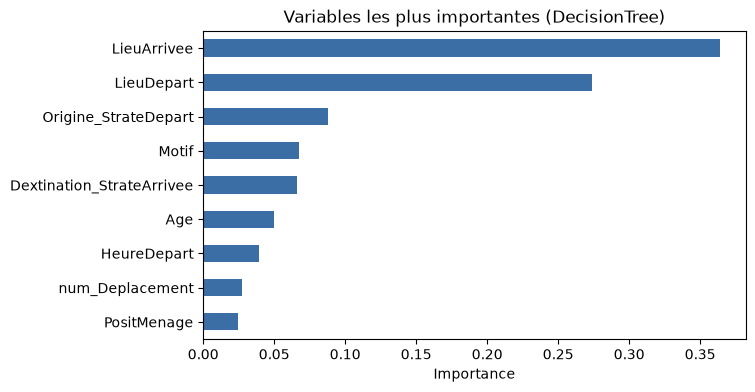

In [19]:
arbre = fitted.stages[-1]
attrs = pred.schema["features"].metadata["ml_attr"]["attrs"]
noms = {a["idx"]: a["name"] for groupe in attrs.values() for a in groupe}

importance = {}
for i, v in enumerate(arbre.featureImportances.toArray()):
    importance[noms.get(i, "f" + str(i)).replace("_idx", "")] = float(v)

importance = pd.Series(importance)

importance.sort_values().plot(kind="barh", figsize=(7, 4), color="#3b6ea5")
plt.title("Variables les plus importantes (" + modele_retenu + ")")
plt.xlabel("Importance")
plt.show()

**8.3 Où le modèle se trompe-t-il ?** Taux d'erreur par motif (motifs avec au moins 100 déplacements dans le test).

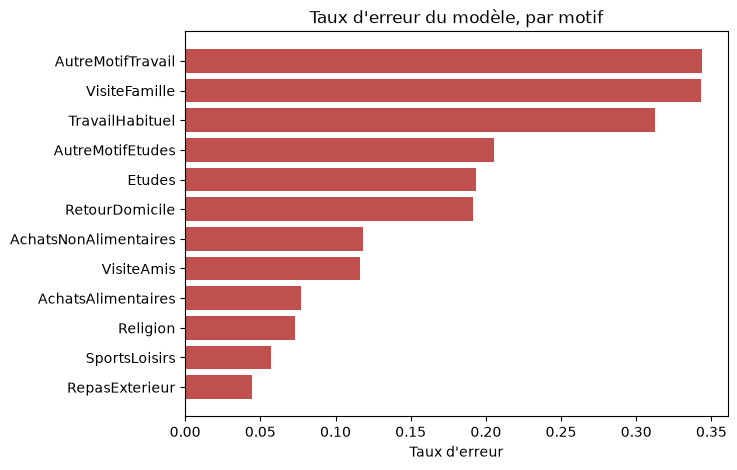

In [20]:
pred = pred.withColumn("erreur", (F.col("label") != F.col("prediction")).cast("int"))
err = (pred.groupBy("Motif").agg(F.count("*").alias("n"), F.avg("erreur").alias("taux_erreur"))
       .toPandas())
err = err[err["n"] >= 100].sort_values("taux_erreur")
plt.figure(figsize=(7, 5))
plt.barh(err["Motif"], err["taux_erreur"], color="#c0504d")
plt.title("Taux d'erreur du modèle, par motif")
plt.xlabel("Taux d'erreur")
plt.show()

## Conclusion
- `Mode1` à `Mode4` sont supprimées et aucune colonne n'est créée : le modèle prédit `NbTrajets` uniquement avec des colonnes d'origine connues avant le déplacement (départ, destination prévue, motif, rang du déplacement, âge, heure de départ, position dans le ménage).
- Les colonnes qui **révèlent** la cible (`Moyen_transport`, `NbTrajets*` par mode) sont exclues, sinon les scores seraient artificiellement parfaits.
- Résultats sur le jeu de test (découpé par ménage) : accuracy ≈ **0,80 à 0,83**, precision pondérée ≈ **0,75 à 0,77**, recall pondéré ≈ **0,80 à 0,83**, F1 pondéré ≈ **0,74 à 0,78** selon le modèle et le scénario.
- Limite importante : la classe « 1 trajet » représente ≈ 83 % des déplacements. Une accuracy proche de 0,83 s'obtiendrait déjà en prédisant toujours « 1 trajet ». Le détail par classe (section 8.1) montre que le modèle reconnaît bien « 1 trajet » mais peu les déplacements à 2, 3 ou 4 trajets (recall faible, surtout pour 4 trajets).
- Les poids de classe (`POIDS_CLASSES = True`) font monter le recall des classes rares, au prix de la precision et de l'accuracy.
- La durée améliore peu les scores et n'est connue qu'après le déplacement : c'est un scénario à part.
- Pistes : régler les hyperparamètres sur un jeu de validation découpé par ménage, tester XGBoost / LightGBM, ou regrouper les classes (1 trajet / 2 trajets ou plus).